## TODO: 

1. Generate a 2D distribution with 3 modes. Generate it as a mixture of 3 inidividual Gaussian distributions. 
2. Generate nice plots of this distribution. Preferably as 3 plots showing the probability landscape. If that is not possible, show 2D plots of the probability density contours. 
3. Next analytically compute the gradients of the density function of this distribution. Overlays plots of the gradient directions over the 2D contour plots of the density.
4. Use the analytical gradients and Langevin dynamics to start from any random point and end up near one of the modal peaks. Plot the trajectory that the sample takes. 
5. Next generate samples from the 2D distribution and now comes the fun part 

In [2]:
# imports
import torch
from matplotlib import pyplot as plt
from torchvision import datasets, transforms

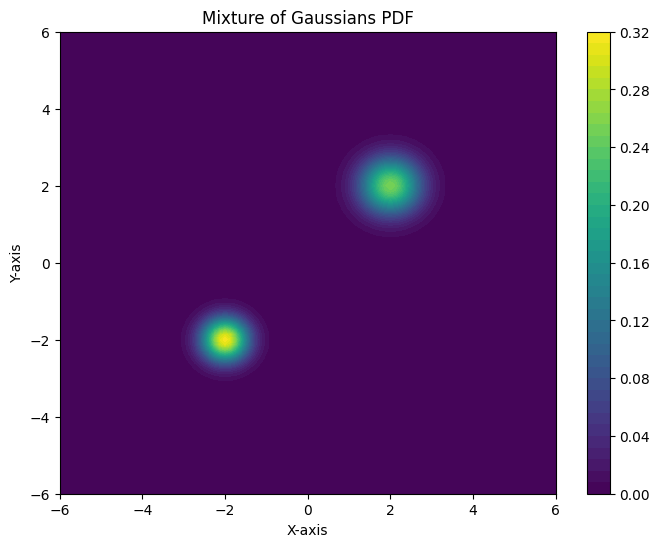

In [26]:
# Create a 2D analytical distribution (e.g., a mixture of Gaussians) with 3 modes

mu_1 = torch.tensor([2.0, 2.0])
mu_2 = torch.tensor([-2.0, -2.0])
mu_3 = torch.tensor([2.0, -2.0])

cov_1 = torch.eye(2) * 0.25
cov_2 = torch.eye(2) * 0.15
cov_3 = torch.eye(2) * 0.75

alpha_1 = 0.4
alpha_2 = 0.3
alpha_3 = 0.3

# Plot the probability density function of the mixture distribution (increase grid resolution)
x = torch.linspace(-6, 6, 100)
y = torch.linspace(-6, 6, 100)

X, Y = torch.meshgrid(x, y)
pos = torch.stack([X, Y], dim=-1)

def gaussian_pdf(pos, mu, cov):
    d = pos - mu
    inv_cov = torch.inverse(cov)
    exponent = -0.5 * torch.einsum('...i,ij,...j->...', d, inv_cov, d)
    normalization = torch.sqrt((2 * torch.pi) ** 2 * torch.det(cov))
    return torch.exp(exponent) / normalization

pdf_1 = gaussian_pdf(pos, mu_1, cov_1)
pdf_2 = gaussian_pdf(pos, mu_2, cov_2)
pdf_3 = gaussian_pdf(pos, mu_3, cov_3)

# Use all three components for the mixture PDF
mixture_pdf = alpha_1 * pdf_1 + alpha_2 * pdf_2  # + alpha_3 * pdf_3

plt.figure(figsize=(8, 6))
plt.contourf(X, Y, mixture_pdf, levels=50, cmap='viridis')
plt.colorbar()
plt.title('Mixture of Gaussians PDF')
plt.xlabel('X-axis')
plt.ylabel('Y-axis')
plt.show()


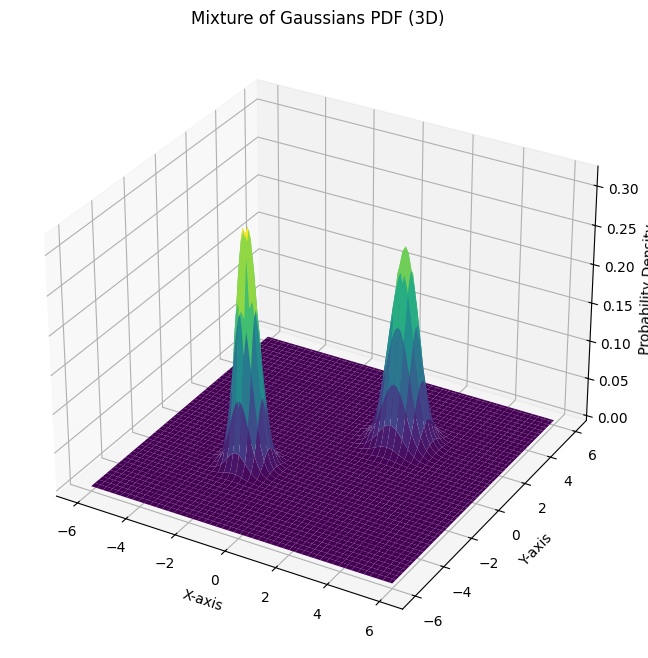

In [27]:
# Plot a 3D surface plot of the mixture distribution
from mpl_toolkits.mplot3d import Axes3D

fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')
ax.plot_surface(X.numpy(), Y.numpy(), mixture_pdf.numpy(), cmap='viridis')
ax.set_title('Mixture of Gaussians PDF (3D)')
ax.set_xlabel('X-axis')
ax.set_ylabel('Y-axis')
ax.set_zlabel('Probability Density')
plt.show() 

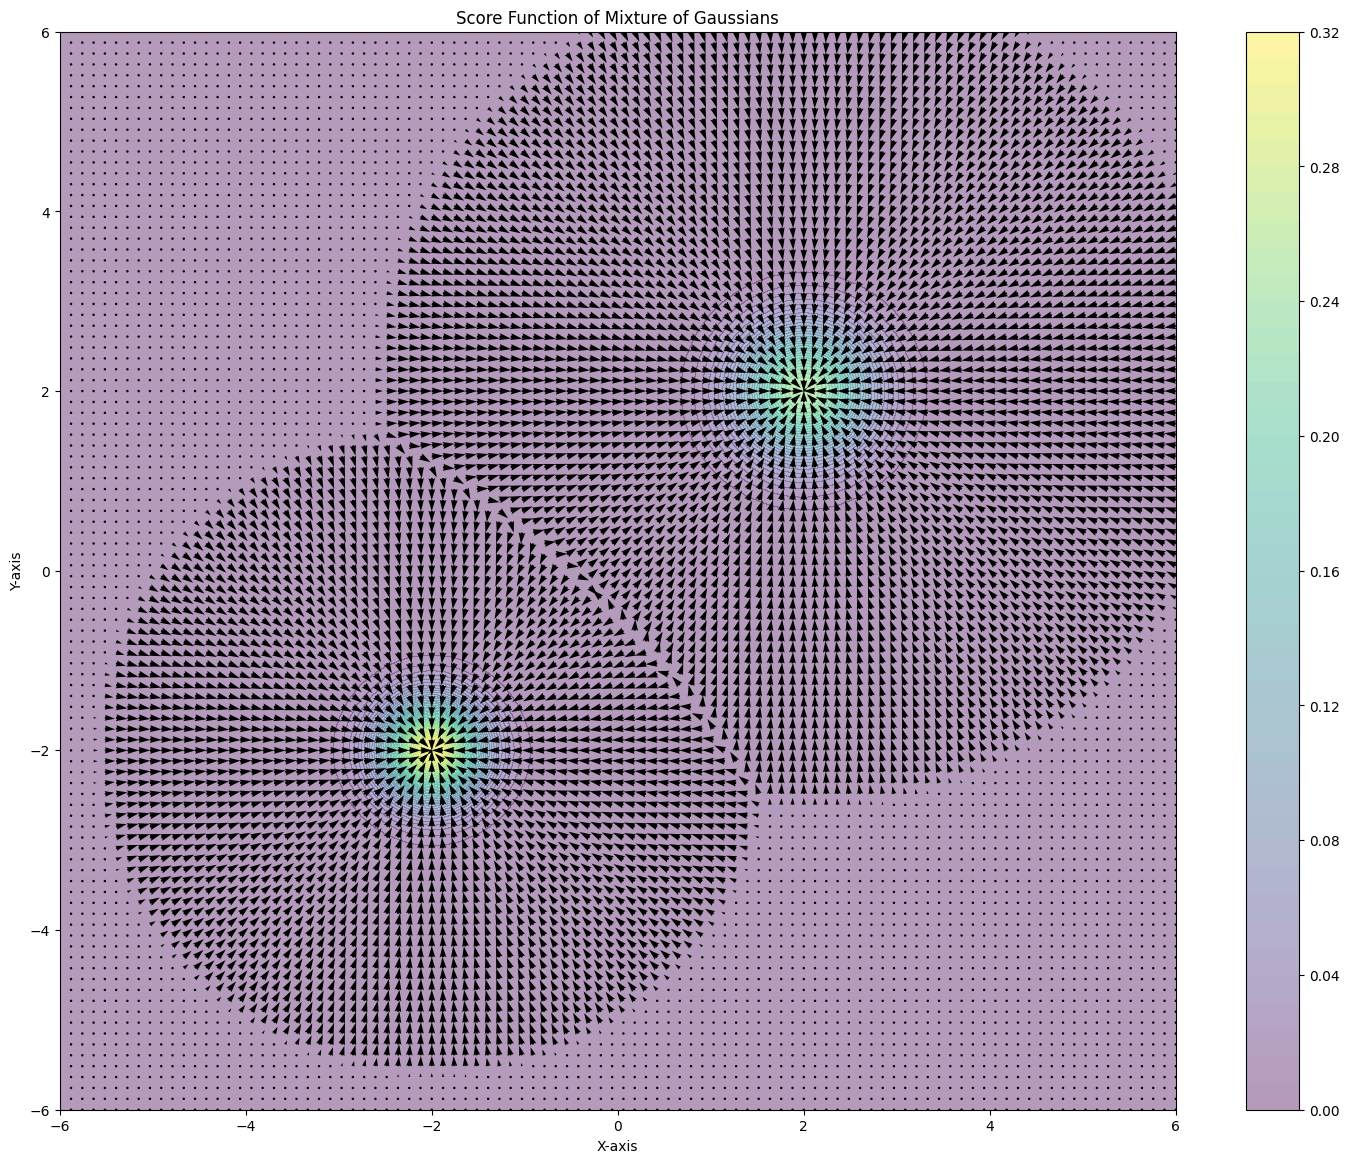

In [29]:
# Compute the score function (gradient of log probability density) for the mixture distribution
def score_function(pos, mu, cov):
    """Compute the score function (gradient of log probability density) for a Gaussian distribution.
    """
    d = pos - mu
    inv_cov = torch.inverse(cov)
    return -torch.einsum('...i,ij->...j', d, inv_cov)

score_1 = score_function(pos, mu_1, cov_1)
score_2 = score_function(pos, mu_2, cov_2)
# score_3 = score_function(pos, mu_3, cov_3)

# Correct mixture score: weighted average of component scores, weighted by component densities
numer = (alpha_1 * pdf_1[..., None] * score_1
         + alpha_2 * pdf_2[..., None] * score_2)
        #  + alpha_3 * pdf_3[..., None] * score_3)
eps = 1e-12
mixture_score = numer / (mixture_pdf[..., None] + eps)

# Visualize the score function as a vector field
plt.figure(figsize=(18, 14))
plt.contourf(X, Y, mixture_pdf, levels=50, cmap='viridis', alpha=0.4)
plt.colorbar()
# normalize for visualization so arrows are legible
norms = torch.norm(mixture_score, dim=-1, keepdim=True)
mixture_score_vis = mixture_score / (norms + 1e-6)
# quiver: use angles='xy' and scale_units='xy' to preserve vector geometry
plt.quiver(X, Y, mixture_score_vis[..., 0], mixture_score_vis[..., 1], color='black',
           angles='xy', scale_units='xy', scale=8)
plt.title('Score Function of Mixture of Gaussians')
plt.xlabel('X-axis')
plt.ylabel('Y-axis')
plt.show()